# 03 - Fitting the Faber-Jackson relation

**Goal:** fit the Faber-Jackson (FJ) relation to the early-type sample from notebook 02 and compare it with published results.

Faber & Jackson (1976) found that the luminosity of an elliptical galaxy scales with its central velocity dispersion as

$$L \propto \sigma^n, \qquad n \approx 4.$$

We measure luminosity with the absolute magnitude $M_r = -2.5\log_{10}L + C$. Substituting gives a straight line:

$$M_r = -2.5\,n\,\log_{10}\sigma + \text{const}$$

So if we fit $M_r$ against $\log_{10}\sigma$, the slope is $-2.5n$ and the FJ exponent is $n = -\text{slope}/2.5$.

We fit with `scipy.stats.linregress`, which is an ordinary least-squares straight-line fit and also returns the error on the slope.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

early = pd.read_csv('../data/processed/sample_early_types.csv')
early['log_sigma'] = np.log10(early['sigma_re'])

print('Early-type galaxies:', len(early))
print(early['morph'].value_counts())

Early-type galaxies: 768
morph
S0      328
E       225
E/S0    215
Name: count, dtype: int64


## 1. Fit the whole early-type sample

In [2]:
fit = stats.linregress(early['log_sigma'], early['m_r'])

n = -fit.slope / 2.5
n_err = fit.stderr / 2.5

print(f'Slope of M_r vs log sigma: {fit.slope:.2f} +/- {fit.stderr:.2f}')
print(f'Intercept: {fit.intercept:.2f} +/- {fit.intercept_stderr:.2f}')
print(f'Correlation coefficient r: {fit.rvalue:.2f}')
print(f'FJ exponent n = {n:.2f} +/- {n_err:.2f}')

Slope of M_r vs log sigma: -4.70 +/- 0.12
Intercept: -10.77 +/- 0.26
Correlation coefficient r: -0.81
FJ exponent n = 1.88 +/- 0.05


To compare with the classic result, we also draw a line with $n = 4$ (slope $-10$) passing through the middle of our data (the median $\log\sigma$ and median $M_r$), so only the steepness is being compared.

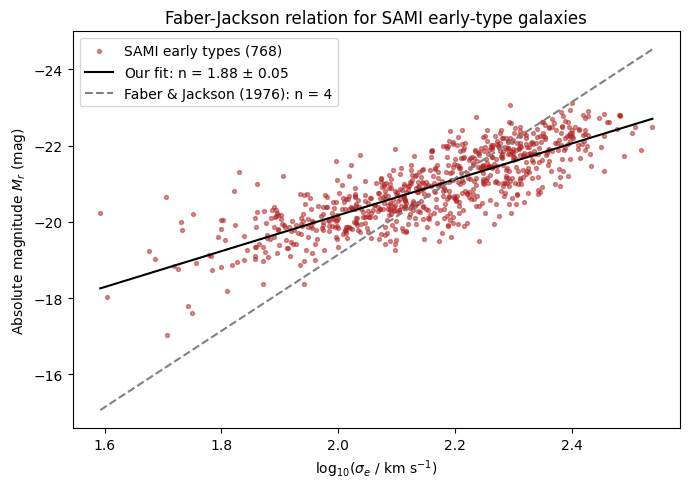

In [3]:
x_line = np.linspace(early['log_sigma'].min(), early['log_sigma'].max(), 100)
y_fit = fit.slope * x_line + fit.intercept
y_n4 = -10 * (x_line - early['log_sigma'].median()) + early['m_r'].median()

plt.figure(figsize=(7, 5))
plt.scatter(early['log_sigma'], early['m_r'], s=8, color='firebrick', alpha=0.5, label=f'SAMI early types ({len(early)})')
plt.plot(x_line, y_fit, color='black', label=f'Our fit: n = {n:.2f} $\\pm$ {n_err:.2f}')
plt.plot(x_line, y_n4, color='grey', linestyle='--', label='Faber & Jackson (1976): n = 4')
plt.gca().invert_yaxis()
plt.xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
plt.ylabel(r'Absolute magnitude $M_r$ (mag)')
plt.title('Faber-Jackson relation for SAMI early-type galaxies')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/04_fj_fit.png', dpi=150)
plt.show()

## 2. Does the direction of the fit matter?

Ordinary least squares assumes all the scatter is in the y variable. Our data have real scatter in both directions (galaxies with the same $\sigma$ have a range of luminosities), so the answer depends on which variable we call y:

- **Forward fit:** $M_r$ against $\log\sigma$ (as above)
- **Inverse fit:** $\log\sigma$ against $M_r$, then turn it around. If $\log\sigma = b\,M_r + c$, then $M_r = (1/b)\log\sigma + \ldots$, so $n = -1/(2.5\,b)$

The forward fit minimises squared residuals in absolute magnitude, while the inverse fit minimises squared residuals in logarithmic velocity dispersion. With scatter in the data, these give different relations.

Older FJ studies often fitted $\log\sigma$ against magnitude, which is one reason their $n$ values were larger.

In [4]:
inv = stats.linregress(early['m_r'], early['log_sigma'])

n_inv = -1 / (2.5 * inv.slope)
n_inv_err = inv.stderr / (2.5 * inv.slope**2)

print(f'Forward fit:  n = {n:.2f} +/- {n_err:.2f}')
print(f'Inverse fit:  n = {n_inv:.2f} +/- {n_inv_err:.2f}')

Forward fit:  n = 1.88 +/- 0.05
Inverse fit:  n = 2.84 +/- 0.07


## 3. Fit each morphological type separately

Ellipticals (E), transition objects (E/S0) and lenticulars (S0) have different structures: S0s have a disk and more rotation. If the FJ relation depends on how a galaxy is supported (random motions vs rotation), the types could give different slopes.

In [5]:
rows = []
groups = [('E', early[early['morph'] == 'E']),
          ('E/S0', early[early['morph'] == 'E/S0']),
          ('S0', early[early['morph'] == 'S0']),
          ('E + E/S0', early[early['morph'] != 'S0']),
          ('All early types', early)]

for name, sub in groups:
    f = stats.linregress(sub['log_sigma'], sub['m_r'])
    b = stats.linregress(sub['m_r'], sub['log_sigma'])
    n_f = -f.slope / 2.5
    n_i = -1 / (2.5 * b.slope)
    rows.append({'sample': name,
                 'N': len(sub),
                 'n_forward': round(n_f, 2),
                 'n_forward_err': round(f.stderr / 2.5, 2),
                 'n_inverse': round(n_i, 2),
                 'n_inverse_err': round(b.stderr / (2.5 * b.slope**2), 2),
                 'r': round(f.rvalue, 2)})

results = pd.DataFrame(rows)
results

,sample,N,n_forward,n_forward_err,n_inverse,n_inverse_err,r
0,E,225,1.93,0.09,2.97,0.15,-0.81
1,E/S0,215,1.91,0.09,2.90,0.14,-0.81
2,S0,328,1.86,0.07,2.63,0.09,-0.84
3,E + E/S0,440,1.93,0.07,2.94,0.10,-0.81
4,All early types,768,1.88,0.05,2.84,0.07,-0.81


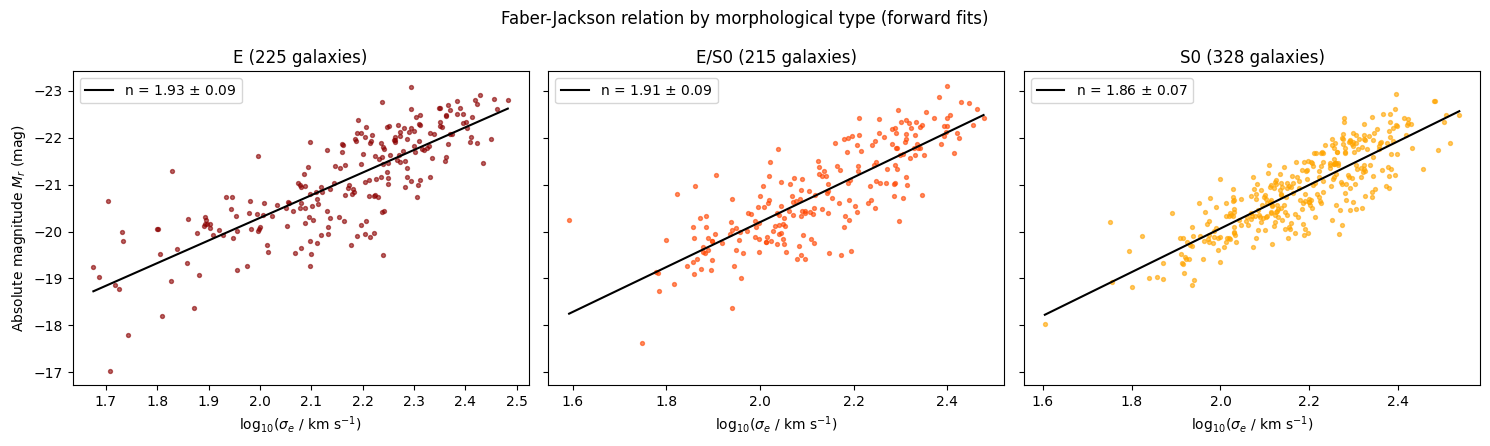

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (name, colour) in zip(axes, [('E', 'darkred'), ('E/S0', 'orangered'), ('S0', 'orange')]):
    sub = early[early['morph'] == name]
    f = stats.linregress(sub['log_sigma'], sub['m_r'])
    x = np.linspace(sub['log_sigma'].min(), sub['log_sigma'].max(), 100)
    ax.scatter(sub['log_sigma'], sub['m_r'], s=8, color=colour, alpha=0.6)
    ax.plot(x, f.slope * x + f.intercept, color='black', label=f'n = {-f.slope/2.5:.2f} $\\pm$ {f.stderr/2.5:.2f}')
    ax.set_title(f'{name} ({len(sub)} galaxies)')
    ax.set_xlabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
    ax.legend()

axes[0].set_ylabel(r'Absolute magnitude $M_r$ (mag)')
axes[0].invert_yaxis()
fig.suptitle('Faber-Jackson relation by morphological type (forward fits)')
plt.tight_layout()
plt.savefig('../figures/05_fj_by_morphology.png', dpi=150)
plt.show()

## 4. Stellar-mass form of the relation

Luminosity depends on the age and metallicity of the stars (the mass-to-light ratio), so many recent studies use stellar mass instead. Oh et al. (2020) give

$$\log_{10}\sigma_e = 0.285\,\log_{10}(M_*/M_\odot) - 0.845$$

for bulge-dominated galaxies. To compare like with like, we fit in the same direction ($\log\sigma$ against $\log M_*$). The SAMI `mstar` column is already $\log_{10}(M_*/M_\odot)$.

In [7]:
mass_fit = stats.linregress(early['mstar'], early['log_sigma'])

print(f'Our slope:  {mass_fit.slope:.3f} +/- {mass_fit.stderr:.3f}')
print(f'Our intercept: {mass_fit.intercept:.3f} +/- {mass_fit.intercept_stderr:.3f}')
print('Oh et al. (2020) slope: 0.285, intercept: -0.845')
print(f'Implied M* proportional to sigma^{1/mass_fit.slope:.2f} (ours) vs sigma^{1/0.285:.2f} (Oh et al.)')

Our slope:  0.342 +/- 0.008
Our intercept: -1.439 +/- 0.083
Oh et al. (2020) slope: 0.285, intercept: -0.845
Implied M* proportional to sigma^2.92 (ours) vs sigma^3.51 (Oh et al.)


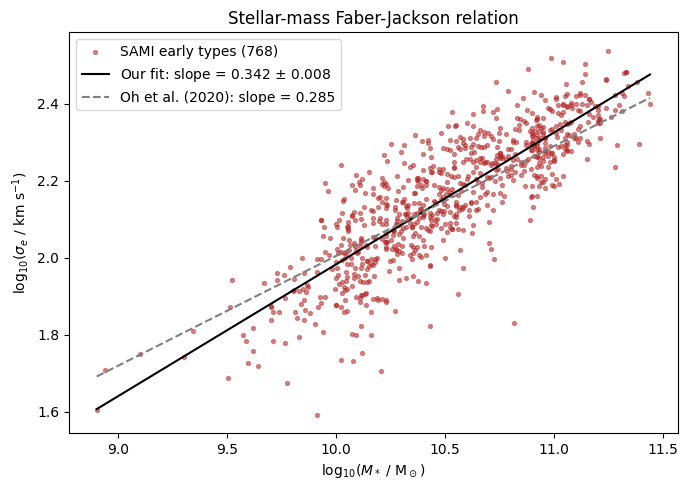

In [8]:
m_line = np.linspace(early['mstar'].min(), early['mstar'].max(), 100)

plt.figure(figsize=(7, 5))
plt.scatter(early['mstar'], early['log_sigma'], s=8, color='firebrick', alpha=0.5, label=f'SAMI early types ({len(early)})')
plt.plot(m_line, mass_fit.slope * m_line + mass_fit.intercept, color='black', label=f'Our fit: slope = {mass_fit.slope:.3f} $\\pm$ {mass_fit.stderr:.3f}')
plt.plot(m_line, 0.285 * m_line - 0.845, color='grey', linestyle='--', label='Oh et al. (2020): slope = 0.285')
plt.xlabel(r'log$_{10}$($M_*$ / M$_\odot$)')
plt.ylabel(r'log$_{10}$($\sigma_e$ / km s$^{-1}$)')
plt.title('Stellar-mass Faber-Jackson relation')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/06_fj_stellar_mass.png', dpi=150)
plt.show()

## 5. Save the fit results

In [9]:
mass_row = pd.DataFrame([{'sample': 'All early types (log sigma vs log M*)',
                          'N': len(early),
                          'mass_slope': round(mass_fit.slope, 3),
                          'mass_slope_err': round(mass_fit.stderr, 3),
                          'mass_intercept': round(mass_fit.intercept, 3)}])

results.to_csv('../data/processed/fj_fit_results.csv', index=False)
mass_row.to_csv('../data/processed/fj_mass_fit_results.csv', index=False)
print('Saved fit results to data/processed/')

Saved fit results to data/processed/


## 6. Summary

| Fit | Our result | Literature |
|---|---|---|
| FJ exponent $n$, forward fit ($M_r$ vs $\log\sigma$) | 1.88 ± 0.05 | 4 (Faber & Jackson 1976) |
| FJ exponent $n$, inverse fit | 2.84 ± 0.07 | |
| $\log\sigma$ vs $\log M_*$ slope | 0.342 ± 0.008 | 0.285 (Oh et al. 2020) |

- There is a clear, tight correlation ($r = -0.81$): brighter, more massive early-type galaxies have larger stellar velocity dispersions, as expected.
- Our FJ exponent is well below the classic $n = 4$, whichever way we fit. The direction of the fit alone changes $n$ from about 1.9 to 2.8, so the fitting method has to be stated when comparing with published values.
- E, E/S0 and S0 galaxies give very similar exponents. S0s are slightly shallower, which could be because some of their support comes from rotation (a disk) rather than random motions.
- In the stellar-mass form, our slope is steeper than Oh et al. (2020), but the two lines cross in the middle of our mass range and differ most for low-mass galaxies.

Possible reasons our $n$ is lower than 4:
1. **Fitting direction.** Forward least-squares fits give the shallowest slope.
2. **Luminosity range.** SAMI includes many lower-luminosity early types. The original FJ sample was mostly bright ellipticals, and the relation is known to be shallower for fainter galaxies.
3. **Band and aperture.** We use r-band magnitudes and σ within one effective radius. Faber & Jackson used B-band and central dispersions.
4. **Sample selection.** Including S0s and E/S0s, and our quality cuts, changes which galaxies are fitted.

We test some of these in the next notebook.